# Canny Edge Detection

How close is a detected edge to the actual boundary of a noisy shape? A synthetic mask supplies the location to within a pixel.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Boundary matching

Precision credits a detected pixel within 1.5 pixels of a reference edge. Recall applies the same rule in the opposite direction.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.feature import canny
from gallery.vision import shapes


def boundary_counts(mask, edge, tolerance=1.5):
    actual = mask ^ ndi.binary_erosion(mask)
    precise = (edge & (ndi.distance_transform_edt(~actual) <= tolerance)).sum()
    recalled = (
        (actual & (ndi.distance_transform_edt(~edge) <= tolerance)).sum() if edge.any() else 0
    )
    return precise, edge.sum(), recalled, actual.sum()

## Compare outlines

The thresholds are fixed across 80 newly drawn images.

Boundary precision 0.274 | Recall 0.996 | F1 0.430


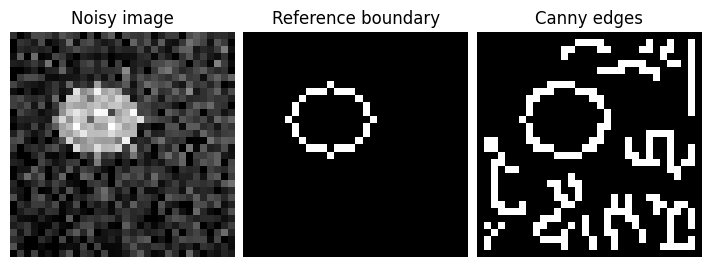

In [3]:
images, masks = shapes(80, 31)
edges = [canny(img, sigma=1.2, low_threshold=0.10, high_threshold=0.20) for img in images]
matches, detected, recovered, reference = np.sum(
    [boundary_counts(m, e) for m, e in zip(masks, edges)], axis=0
)
precision, recall = matches / detected, recovered / reference
print(
    f"Boundary precision {precision:.3f} | Recall {recall:.3f} | F1 {2*precision*recall/(precision+recall):.3f}"
)
fig, axes = plt.subplots(1, 3, figsize=(7, 2.5), constrained_layout=True)
for ax, img, title in zip(
    axes,
    [images[3], masks[3] ^ ndi.binary_erosion(masks[3]), edges[3]],
    ["Noisy image", "Reference boundary", "Canny edges"],
):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

## Reading the result

A one-pixel contour shift has little visual effect at this resolution. Matching with a tolerance makes that choice explicit.

## References

[Canny, A Computational Approach to Edge Detection (1986)](https://doi.org/10.1109/TPAMI.1986.4767851)

[scikit-image, Canny edge detection](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.canny)

[Image and video generators and evaluation](../../../gallery/vision.py)